## My question: 
Whats the probability that an AI agent randomly runs into a ghost  in the Atari game "pacman", runs into the ghost in the fist 5 to 10 seconds?

## Description
 Let $X$ be the time elapsed (in seconds) from the start of a game until the AI agent collides with a ghost for the first time.

A single simulated play-through of Atari Pac-Man where an AI agent chooses actions at random from the start of the game until it collides with a ghost.

Possible Outcomes:

Success (In Interval): The time of collision 
X falls within the interval 
[5,10] seconds (
5≤X≤10).

Failure (Outside Interval): The time of collision 
X occurs in less than 5 seconds (
X<5) or takes longer than 10 seconds (
X>10).

## !pip install gymnasium
!pip install "gymnasium[atari]"
!pip install ale-py
!pip install autorom[accept-rom-license]

# RESTART YOUR KERNEL AND THEN RUN THE REST OF THE PROGRAM.
# DO NOT PERFORM THE INSTALLATIONS AGAIN

## Analysis

In [1]:
import ale_py
import gymnasium as gym

# Register the ALE environments
gym.register_envs(ale_py)

# Now check the registry
gym.pprint_registry()

===== classic_control =====
Acrobot-v1                  CartPole-v0                 CartPole-v1
MountainCar-v0              MountainCarContinuous-v0    Pendulum-v1
===== phys2d =====
phys2d/CartPole-v0          phys2d/CartPole-v1          phys2d/Pendulum-v0
===== box2d =====
BipedalWalker-v3            BipedalWalkerHardcore-v3    CarRacing-v3
LunarLander-v3              LunarLanderContinuous-v3
===== toy_text =====
Blackjack-v1                CliffWalking-v1             CliffWalkingSlippery-v1
FrozenLake-v1               FrozenLake8x8-v1            Taxi-v4
===== tabular =====
tabular/Blackjack-v0        tabular/CliffWalking-v0
===== None =====
Ant-v2                      Ant-v3                      GymV21Environment-v0
GymV26Environment-v0        HalfCheetah-v2              HalfCheetah-v3
Hopper-v2                   Hopper-v3                   Humanoid-v2
Humanoid-v3                 HumanoidStandup-v2          InvertedDoublePendulum-v2
InvertedPendulum-v2         Pusher-v2             

In [2]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time

In [3]:
# Create environment
env = gym.make('ALE/Pacman-v5', render_mode='rgb_array')
observation, info = env.reset()

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

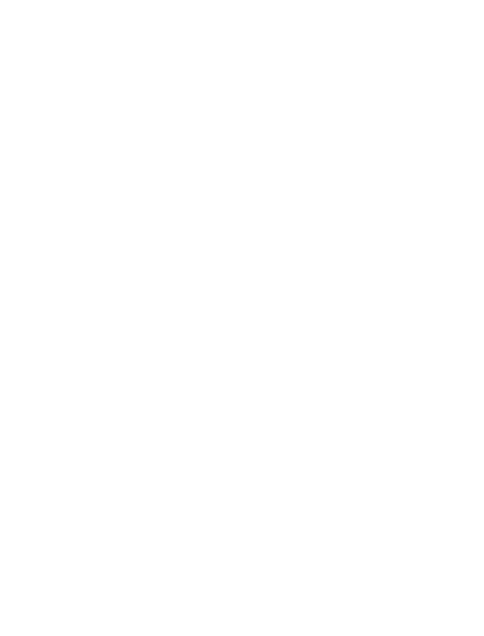

In [4]:
# Create game window
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')

In [47]:
import math

In [48]:
env = gym.make('ALE/Pacman-v5')

In [57]:
successes = 0
total_games = 1000
times = []

In [58]:
for game in range(total_games):
    observation, info = env.reset()
    starting_lives = info['lives']
    steps = 0
    
    while True:
        action = env.action_space.sample()
        observation, reward, terminated, truncated, info = env.step(action)
        steps = steps + 1
        
        if info['lives'] < starting_lives:
            seconds = steps / 15
            times.append(seconds)
            
            # Individual game probability for 5 to 10 seconds
            if 5 <= seconds <= 10:
                successes = successes + 1
            break
            
        if terminated or truncated:
            break

env.close()

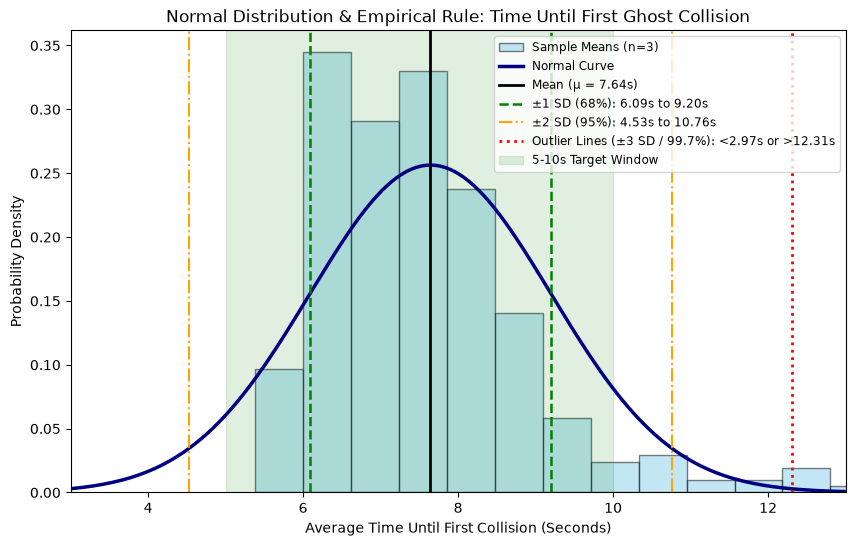

In [59]:
batch_size = 3
sample_means = [sum(times[i:i + batch_size]) / batch_size for i in range(0, len(times) - batch_size + 1, batch_size)]

mean_val = sum(sample_means) / len(sample_means)
std_val = math.sqrt(sum((x - mean_val) ** 2 for x in sample_means) / len(sample_means))

plt.figure(figsize=(10, 6))

plt.hist(sample_means, bins=20, density=True, edgecolor='black', alpha=0.5, color='skyblue', label=f'Sample Means (n={batch_size})')

x_vals = [mean_val - 4*std_val + i*(8*std_val/200) for i in range(201)]
y_vals = [(1 / (std_val * math.sqrt(2 * math.pi))) * math.exp(-0.5 * ((x - mean_val) / std_val) ** 2) for x in x_vals]
plt.plot(x_vals, y_vals, color='navy', linewidth=2.5, label='Normal Curve')

plt.axvline(mean_val, color='black', linestyle='-', linewidth=2, label=f'Mean (μ = {mean_val:.2f}s)')

plt.axvline(mean_val - std_val, color='green', linestyle='--', linewidth=1.8, label=f'±1 SD (68%): {mean_val - std_val:.2f}s to {mean_val + std_val:.2f}s')
plt.axvline(mean_val + std_val, color='green', linestyle='--', linewidth=1.8)

plt.axvline(mean_val - 2*std_val, color='orange', linestyle='-.', linewidth=1.5, label=f'±2 SD (95%): {mean_val - 2*std_val:.2f}s to {mean_val + 2*std_val:.2f}s')
plt.axvline(mean_val + 2*std_val, color='orange', linestyle='-.', linewidth=1.5)

plt.axvline(mean_val - 3*std_val, color='red', linestyle=':', linewidth=2, label=f'Outlier Lines (±3 SD / 99.7%): <{mean_val - 3*std_val:.2f}s or >{mean_val + 3*std_val:.2f}s')
plt.axvline(mean_val + 3*std_val, color='red', linestyle=':', linewidth=2)

plt.axvspan(5, 10, color='green', alpha=0.12, label='5-10s Target Window')

plt.title('Normal Distribution & Empirical Rule: Time Until First Ghost Collision')
plt.xlabel('Average Time Until First Collision (Seconds)')
plt.ylabel('Probability Density')
plt.xlim(3, 13)  # Widened x-axis so values below 5s and above 10s are clearly visible
plt.legend(loc='upper right', fontsize=8.5)
plt.show()


In [60]:
print(f"Mean (μ): {mean_val:.2f}s | Standard Deviation (σ): {std_val:.2f}s")
print(f"68% of data (±1 SD): {mean_val - std_val:.2f}s to {mean_val + std_val:.2f}s")
print(f"95% of data (±2 SD): {mean_val - 2*std_val:.2f}s to {mean_val + 2*std_val:.2f}s")
print(f"Outliers (outside ±3 SD / 99.7%): < {mean_val - 3*std_val:.2f}s or > {mean_val + 3*std_val:.2f}s")

Mean (μ): 7.64s | Standard Deviation (σ): 1.56s
68% of data (±1 SD): 6.09s to 9.20s
95% of data (±2 SD): 4.53s to 10.76s
Outliers (outside ±3 SD / 99.7%): < 2.97s or > 12.31s


In [61]:
# 1. EMPIRICAL PROBABILITY 
emp_single_prob = sum(1 for t in times if 5 <= t <= 10) / len(times)

# Sample-mean empirical probability (5 to 10 seconds)
emp_sample_prob = sum(1 for m in sample_means if 5 <= m <= 10) / len(sample_means)

In [62]:
# 2. THEORETICAL PROBABILITY 
def normal_cdf(x, mu, sigma):
    z = (x - mu) / (sigma * math.sqrt(2))
    return 0.5 * (1 + math.erf(z))

In [63]:
# Calculate P(5 <= X <= 10) = CDF(10) - CDF(5)
theo_prob = normal_cdf(10, mean_val, std_val) - normal_cdf(5, mean_val, std_val)

In [64]:
# Print comparison results
print("--- PROBABILITY COMPARISON (5 to 10 Seconds) ---")
print(f"Empirical Probability (Individual Games): {emp_single_prob:.4f} ({emp_single_prob * 100:.2f}%)")
print(f"Empirical Probability (Sample Means):     {emp_sample_prob:.4f} ({emp_sample_prob * 100:.2f}%)")
print(f"Theoretical Probability (Normal Curve):   {theo_prob:.4f} ({theo_prob * 100:.2f}%)")
print(f"Difference (Sample Empirical vs. Theoretical): {abs(emp_sample_prob - theo_prob):.4f}")

--- PROBABILITY COMPARISON (5 to 10 Seconds) ---
Empirical Probability (Individual Games): 0.8890 (88.90%)
Empirical Probability (Sample Means):     0.9399 (93.99%)
Theoretical Probability (Normal Curve):   0.8903 (89.03%)
Difference (Sample Empirical vs. Theoretical): 0.0496


## Conclusion
The theretical and empirical probability are both very close too eachother being 4% . and they are very close to what I got from my simulation being this far off. 

In my graph I have 20 bins, really helping explain what my findings are. You might say my data is skewed but it is impossible for the ghost to reach pacman in the first 5 seconds of the game. This is why there is no data there. The bell is set up to the best. The STD is ___, and the mean is __, and I would say __% is between 5-10 seconds based on the empirical rule. The graph was a great tool to use when understaning what data is in my range. I was able to use a highlighted green background to really show this, which you can clearly see on my graph